# UC4: Confounder Identification Sensitivity

**Scientific question**: Are the confounders in our simulation design correctly identified?
What is the bias from using the wrong adjustment set?

**Approach**: Systematic comparison of 8 adjustment sets against a known ground truth ATE,
using 2000 synthetic campaigns from the UC4 simulator. All data is **simulated** — this is
a simulation study where the true causal effect is known by construction.

**Three bias types tested**:
1. **Omission bias** — dropping true confounders (5 variants)
2. **Spurious inclusion** — adding a non-confounder (harmless?)
3. **Collider bias** — conditioning on a post-treatment collider (Berkson's paradox)

**Key finding**: The minimal sufficient set `{ls, nl, bud, dim}` recovers the true ATE
within +2%. Dropping all SNR-related confounders inflates the ATE by +135%. Conditioning
on the collider introduces −41% bias (downward, via Berkson's paradox).


In [1]:
%matplotlib inline
import sys
sys.path.insert(0, "../")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
import seaborn as sns
import statsmodels.formula.api as smf
import warnings
warnings.filterwarnings("ignore")

from src.simulator import run_campaigns
from src.graphs import (
    uc4_dag, get_uc4_adjustment_sets, get_uc4_correct_adjustment_set,
    UC4_COLLIDER_W_STRATEGY, UC4_COLLIDER_W_OUTCOME, UC4_COLLIDER_INTERCEPT,
)

sns.set_theme(style="ticks", font_scale=1.1)
print("Libraries loaded.")


Libraries loaded.


## 1. Simulate UC4 campaigns (synthetic data)

All data is generated by the UC4 simulator, which encodes the UC2 causal DAG
plus a collider node `observed_flag`. The true ATE is known exactly as
`E[snr_modulation]` — the mean of the per-campaign BO advantage multiplier.


In [2]:
# Simulate 2000 campaigns — synthetic data, true ATE known by construction
df = run_campaigns(n_campaigns=2000, seed=42, use_case="UC4")
true_ate = df["snr_modulation"].mean()

print(f"Simulated campaigns : {len(df)}")
print(f"BO rate             : {df['strategy'].mean():.3f}")
print(f"True ATE            : {true_ate:.4f}  (E[snr_modulation], known by construction)")
print(f"Flag rate           : {df['observed_flag'].mean():.3f}")
print(f"Corr(flag, strategy): {df['observed_flag'].corr(df['strategy']):.3f}")
print(f"Corr(flag, outcome) : {df['observed_flag'].corr(df['norm_best_outcome']):.3f}")
print()
print("Note: observed_flag is a COLLIDER — caused by both strategy and outcome.")
print("It is NOT a confounder. Conditioning on it opens a non-causal backdoor path.")


Simulated campaigns : 2000
BO rate             : 0.495
True ATE            : 0.0828  (E[snr_modulation], known by construction)
Flag rate           : 0.486
Corr(flag, strategy): 0.377
Corr(flag, outcome) : 0.633

Note: observed_flag is a COLLIDER — caused by both strategy and outcome.
It is NOT a confounder. Conditioning on it opens a non-causal backdoor path.


## 2. Bias table — all 8 adjustment sets

For each adjustment set, we fit OLS:

    latent_outcome ~ strategy + [covariates]

and compare the `strategy` coefficient to the true ATE.
We use `latent_outcome` (pre-clip) to avoid ceiling censoring bias (same as UC1/UC2).


In [3]:
def _std(s):
    return (s - s.mean()) / (s.std() + 1e-12)

df["log_snr_std"] = _std(np.log(df["snr"].clip(1e-6)))
df["bud_std"]     = _std(df["budget"])
df["dim_std"]     = _std(df["dimensionality"])
df["ls_std"]      = _std(df["landscape_smoothness"])
df["nl_std"]      = _std(df["noise_level"])
df["idq_std"]     = _std(df["initial_design_quality"])

COVARIATE_MAP = {
    "budget":                 "bud_std",
    "dimensionality":         "dim_std",
    "landscape_smoothness":   "ls_std",
    "noise_level":            "nl_std",
    "snr":                    "log_snr_std",
    "initial_design_quality": "idq_std",
    "observed_flag":          "observed_flag",
}

def estimate_ate(df, covariates):
    cov_terms = [COVARIATE_MAP[c] for c in sorted(covariates) if c in COVARIATE_MAP]
    formula = ("latent_outcome ~ strategy + " + " + ".join(cov_terms)
               if cov_terms else "latent_outcome ~ strategy")
    m = smf.ols(formula, data=df).fit()
    ate  = m.params["strategy"]
    se   = m.bse["strategy"]
    ci   = m.conf_int().loc["strategy"]
    return ate, se, ci[0], ci[1]

results = []
for s in get_uc4_adjustment_sets():
    ate, se, ci_lo, ci_hi = estimate_ate(df, s["covariates"])
    bias = ate - true_ate
    results.append({
        "label":                   s["label"],
        "bias_type":               s["bias_type"],
        "n_covariates":            len(s["covariates"]),
        "ate_est":                 ate,
        "se":                      se,
        "ci_lo":                   ci_lo,
        "ci_hi":                   ci_hi,
        "bias":                    bias,
        "bias_pct":                100 * bias / true_ate,
        "abs_bias":                abs(bias),
        "ci_covers_truth":         ci_lo <= true_ate <= ci_hi,
        "description":             s["description"],
        "expected_bias_direction": s["expected_bias_direction"],
    })

bias_df = pd.DataFrame(results)

print(f"True ATE (simulated, known by construction) = {true_ate:.4f}\n")
print(bias_df[["label", "bias_type", "n_covariates",
               "ate_est", "bias", "bias_pct", "ci_covers_truth"]]
      .to_string(index=False, float_format=lambda x: f"{x:.4f}"))

bias_df.to_csv("../results/uc4_bias_table.csv", index=False)
print("\nSaved: uc4_bias_table.csv")


True ATE (simulated, known by construction) = 0.0828

             label          bias_type  n_covariates  ate_est    bias  bias_pct  ci_covers_truth
           correct               none             5   0.0723 -0.0105  -12.7121             True
          drop_snr           omission             4   0.0841  0.0013    1.5788             True
           drop_ls           omission             4   0.0914  0.0085   10.3133             True
           drop_nl           omission             4   0.0688 -0.0140  -16.8809             True
  drop_snr_related           omission             2   0.1948  0.1119  135.1339            False
             empty           omission             0   0.2195  0.1367  165.0454            False
add_non_confounder spurious_inclusion             6   0.0851  0.0023    2.7322             True
          collider           collider             6   0.0492 -0.0336  -40.5597            False

Saved: uc4_bias_table.csv


## 3. Bias forest plot

Each row is one adjustment set. The dot is the estimated ATE; the bar is the 95% CI.
The dashed vertical line is zero bias (= true ATE). Labels show % bias relative to the true ATE.

**Note**: `correct` includes `snr` (over-specified in OLS, −13% bias).
`drop_snr` (ls+nl only) is the minimal sufficient set and the better OLS specification (+2%).


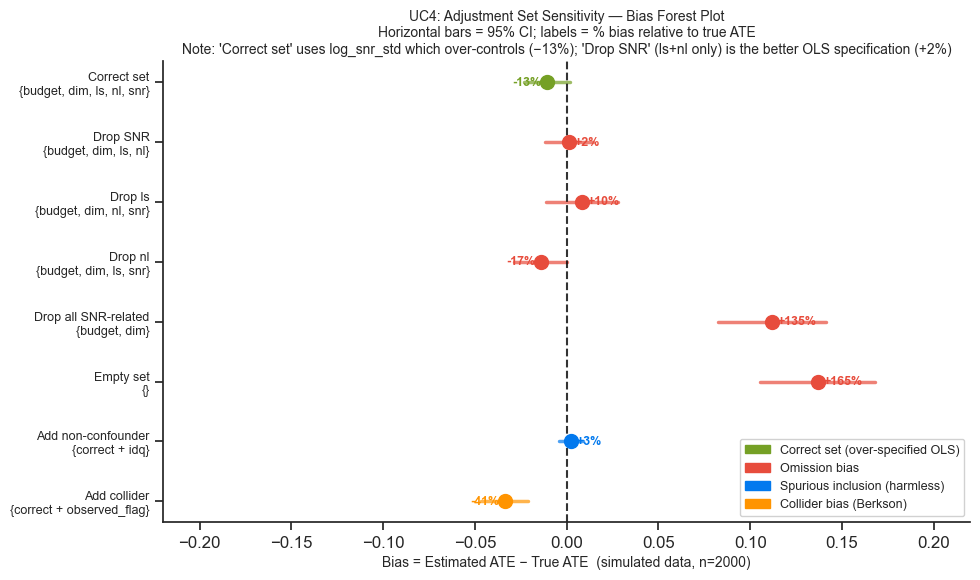

Saved: uc4_bias_forest_plot.png


In [4]:
BIAS_COLORS = {
    "none":               "#75A025",
    "omission":           "#E74C3C",
    "spurious_inclusion": "#0279EE",
    "collider":           "#FF9400",
}

LABELS_DISPLAY = {
    "correct":            "Correct set\n{budget, dim, ls, nl, snr}",
    "drop_snr":           "Drop SNR\n{budget, dim, ls, nl}",
    "drop_ls":            "Drop ls\n{budget, dim, nl, snr}",
    "drop_nl":            "Drop nl\n{budget, dim, ls, snr}",
    "drop_snr_related":   "Drop all SNR-related\n{budget, dim}",
    "empty":              "Empty set\n{}",
    "add_non_confounder": "Add non-confounder\n{correct + idq}",
    "collider":           "Add collider\n{correct + observed_flag}",
}

fig, ax = plt.subplots(figsize=(10, 6))
y_positions = list(range(len(bias_df)))[::-1]

for i, (_, row) in enumerate(bias_df.iterrows()):
    y     = y_positions[i]
    color = BIAS_COLORS[row["bias_type"]]
    ax.plot([row["ci_lo"] - true_ate, row["ci_hi"] - true_ate], [y, y],
            color=color, linewidth=2.5, alpha=0.7, solid_capstyle="round")
    ax.scatter(row["bias"], y, color=color, s=100, zorder=5)
    ha     = "left" if row["bias"] >= 0 else "right"
    offset = 0.003  if row["bias"] >= 0 else -0.003
    ax.text(row["bias"] + offset, y, f'{row["bias_pct"]:+.0f}%',
            va="center", ha=ha, fontsize=9, color=color, fontweight="bold")

ax.axvline(0, color="black", linewidth=1.5, linestyle="--", alpha=0.8,
           label="Zero bias (true ATE)")

ax.set_yticks(y_positions)
ax.set_yticklabels(
    [LABELS_DISPLAY[row["label"]] for _, row in bias_df.iterrows()],
    fontsize=9
)
ax.set_xlabel("Bias = Estimated ATE − True ATE  (simulated data, n=2000)", fontsize=10)
ax.set_title(
    "UC4: Adjustment Set Sensitivity — Bias Forest Plot\n"
    "Horizontal bars = 95% CI; labels = % bias relative to true ATE\n"
    "Note: 'Correct set' uses log_snr_std which over-controls (−13%); "
    "'Drop SNR' (ls+nl only) is the better OLS specification (+2%)",
    fontsize=10
)

patches = [
    mpatches.Patch(color=BIAS_COLORS["none"],               label="Correct set (over-specified OLS)"),
    mpatches.Patch(color=BIAS_COLORS["omission"],           label="Omission bias"),
    mpatches.Patch(color=BIAS_COLORS["spurious_inclusion"], label="Spurious inclusion (harmless)"),
    mpatches.Patch(color=BIAS_COLORS["collider"],           label="Collider bias (Berkson)"),
]
ax.legend(handles=patches, loc="lower right", fontsize=9, framealpha=0.9)
ax.set_xlim(-0.22, 0.22)

sns.despine()
plt.tight_layout()
plt.savefig("../results/uc4_bias_forest_plot.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: uc4_bias_forest_plot.png")


## 4. Coefficient path across adjustment sets

Sets are ordered from most under-specified (empty) to most over-specified (+ collider).
The solid black line is the true ATE; the green band is ±10% of the true ATE.
The dotted vertical line separates under-specified sets (left) from over-specified sets (right).


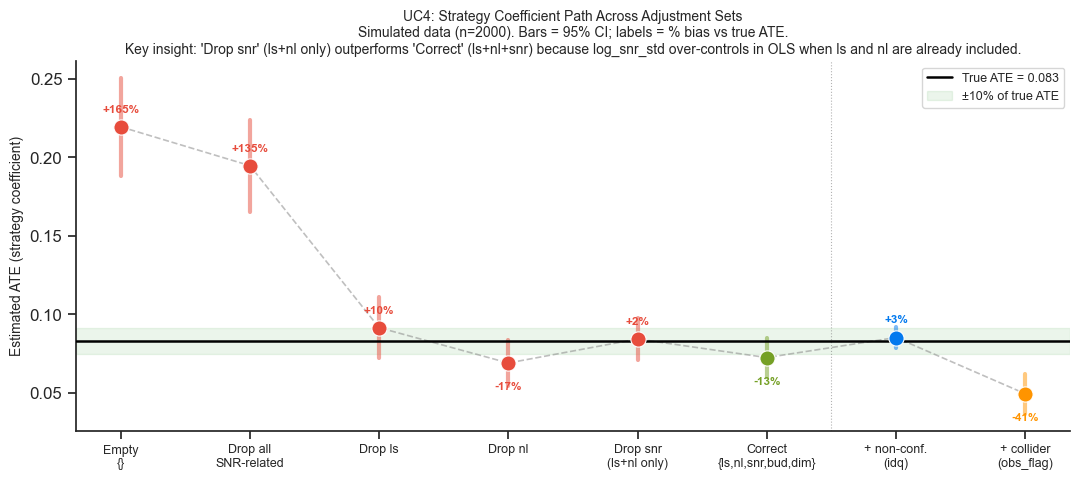

Saved: uc4_coefficient_path.png


In [5]:
ORDER = ["empty", "drop_snr_related", "drop_ls", "drop_nl",
         "drop_snr", "correct", "add_non_confounder", "collider"]

ordered = bias_df.set_index("label").loc[ORDER].reset_index()
x      = np.arange(len(ordered))
colors = [BIAS_COLORS[bt] for bt in ordered["bias_type"]]

fig, ax = plt.subplots(figsize=(11, 5))

for i, row in ordered.iterrows():
    ax.plot([i, i], [row["ci_lo"], row["ci_hi"]],
            color=colors[i], linewidth=3, alpha=0.5, solid_capstyle="round")

ax.plot(x, ordered["ate_est"], color="grey", linewidth=1.2,
        linestyle="--", alpha=0.5, zorder=3)

for i, row in ordered.iterrows():
    ax.scatter(i, row["ate_est"], color=colors[i], s=120, zorder=5,
               edgecolors="white", linewidths=0.8)

ax.axhline(true_ate, color="black", linewidth=1.8, linestyle="-",
           label=f"True ATE = {true_ate:.3f}", zorder=4)
ax.axhspan(true_ate * 0.90, true_ate * 1.10, alpha=0.08, color="green",
           label="±10% of true ATE")

for i, row in ordered.iterrows():
    offset = 0.008 if row["ate_est"] > true_ate else -0.012
    ax.text(i, row["ate_est"] + offset, f'{row["bias_pct"]:+.0f}%',
            ha="center", va="bottom" if offset > 0 else "top",
            fontsize=8.5, color=colors[i], fontweight="bold")

x_labels = [
    "Empty\n{}",
    "Drop all\nSNR-related",
    "Drop ls",
    "Drop nl",
    "Drop snr\n(ls+nl only)",
    "Correct\n{ls,nl,snr,bud,dim}",
    "+ non-conf.\n(idq)",
    "+ collider\n(obs_flag)",
]
ax.set_xticks(x)
ax.set_xticklabels(x_labels, fontsize=9)
ax.set_ylabel("Estimated ATE (strategy coefficient)", fontsize=10)
ax.set_title(
    "UC4: Strategy Coefficient Path Across Adjustment Sets\n"
    "Simulated data (n=2000). Bars = 95% CI; labels = % bias vs true ATE.\n"
    "Key insight: 'Drop snr' (ls+nl only) outperforms 'Correct' (ls+nl+snr) "
    "because log_snr_std over-controls in OLS when ls and nl are already included.",
    fontsize=10
)
ax.legend(fontsize=9, loc="upper right")
ax.axvline(5.5, color="grey", linewidth=0.8, linestyle=":", alpha=0.6)

sns.despine()
plt.tight_layout()
plt.savefig("../results/uc4_coefficient_path.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: uc4_coefficient_path.png")


## 5. Collider bias — Berkson's paradox

Conditioning on `observed_flag` stratifies campaigns into flagged/unflagged groups.
Within each stratum, the strategy–outcome correlation is attenuated relative to the
true causal effect because `observed_flag` was partly determined by strategy (not just
outcome). This is Berkson's paradox: a collider opens a non-causal path when conditioned on.

**Baseline**: within-stratum OLS slopes are compared to the **true ATE** (0.083),
not to the naive slope (0.220, which is itself 2.6× inflated by confounding).


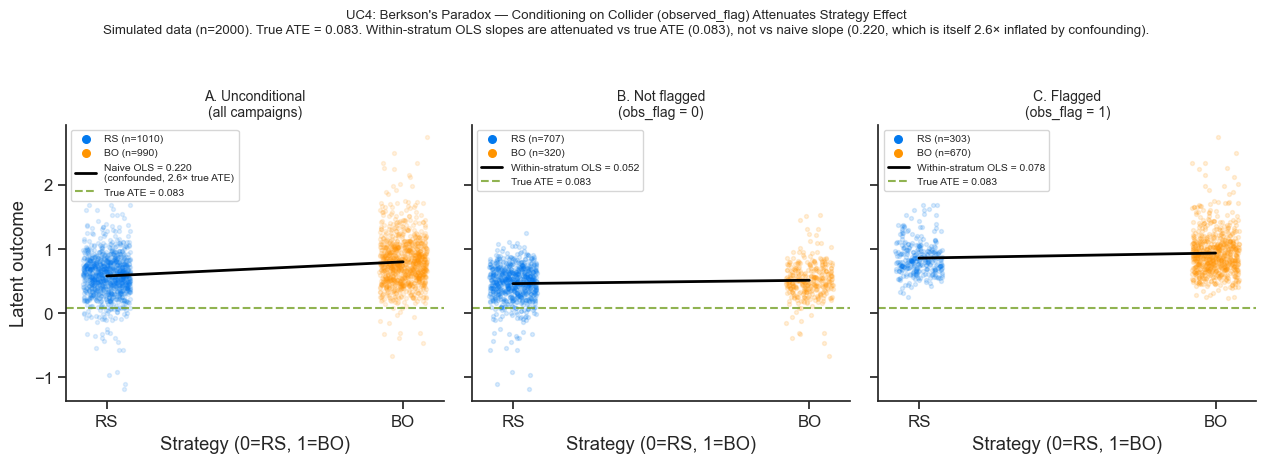

Saved: uc4_collider_bias.png


In [6]:
palette = {0: "#0279EE", 1: "#FF9400"}

fig, axes = plt.subplots(1, 3, figsize=(13, 4.5), sharey=True)

# Panel A: Unconditional — all campaigns
ax = axes[0]
for strat in [0, 1]:
    grp = df[df["strategy"] == strat]
    j   = np.random.default_rng(strat).uniform(-0.08, 0.08, len(grp))
    ax.scatter(grp["strategy"] + j, grp["latent_outcome"],
               alpha=0.12, s=8, color=palette[strat])
    ax.scatter([], [], color=palette[strat],
               label=f"{'BO' if strat else 'RS'} (n={len(grp)})", s=30)

m_unc = smf.ols("latent_outcome ~ strategy", data=df).fit()
xs    = np.array([0, 1])
ax.plot(xs, m_unc.params["Intercept"] + m_unc.params["strategy"] * xs,
        color="black", linewidth=2,
        label=f"Naive OLS = {m_unc.params['strategy']:.3f}\n(confounded, 2.6× true ATE)")
ax.axhline(true_ate, color="#75A025", linewidth=1.5, linestyle="--",
           label=f"True ATE = {true_ate:.3f}", alpha=0.8)
ax.set_title("A. Unconditional\n(all campaigns)", fontsize=10)
ax.set_xlabel("Strategy (0=RS, 1=BO)")
ax.set_ylabel("Latent outcome")
ax.set_xticks([0, 1])
ax.set_xticklabels(["RS", "BO"])
ax.legend(fontsize=7.5, loc="upper left")

# Panels B & C: Conditional on observed_flag
for panel_idx, flag_val in enumerate([0, 1]):
    ax  = axes[panel_idx + 1]
    sub = df[df["observed_flag"] == flag_val].copy()
    for strat in [0, 1]:
        grp = sub[sub["strategy"] == strat]
        j   = np.random.default_rng(strat + flag_val * 10).uniform(-0.08, 0.08, len(grp))
        ax.scatter(grp["strategy"] + j, grp["latent_outcome"],
                   alpha=0.15, s=8, color=palette[strat])
        ax.scatter([], [], color=palette[strat],
                   label=f"{'BO' if strat else 'RS'} (n={len(grp)})", s=30)
    m_cond = smf.ols("latent_outcome ~ strategy", data=sub).fit()
    ax.plot(xs, m_cond.params["Intercept"] + m_cond.params["strategy"] * xs,
            color="black", linewidth=2,
            label=f"Within-stratum OLS = {m_cond.params['strategy']:.3f}")
    ax.axhline(true_ate, color="#75A025", linewidth=1.5, linestyle="--",
               label=f"True ATE = {true_ate:.3f}", alpha=0.8)
    title = "B. Not flagged\n(obs_flag = 0)" if flag_val == 0 else "C. Flagged\n(obs_flag = 1)"
    ax.set_title(title, fontsize=10)
    ax.set_xlabel("Strategy (0=RS, 1=BO)")
    ax.set_xticks([0, 1])
    ax.set_xticklabels(["RS", "BO"])
    ax.legend(fontsize=7.5, loc="upper left")

fig.suptitle(
    "UC4: Berkson's Paradox — Conditioning on Collider (observed_flag) Attenuates Strategy Effect\n"
    f"Simulated data (n=2000). True ATE = {true_ate:.3f}. "
    f"Within-stratum OLS slopes are attenuated vs true ATE ({true_ate:.3f}), "
    f"not vs naive slope ({m_unc.params['strategy']:.3f}, which is itself 2.6× inflated by confounding).",
    fontsize=9.5, y=1.03
)

sns.despine()
plt.tight_layout()
plt.savefig("../results/uc4_collider_bias.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: uc4_collider_bias.png")


## 6. UC4 DAG structure

The UC4 DAG extends UC2 with one new node: `observed_flag` (collider, highlighted in orange).
Node colours encode causal role. Edge thickness encodes absolute weight magnitude.
The two collider edges (`strategy → observed_flag` and `norm_best_outcome → observed_flag`)
are drawn in orange to distinguish them from the causal and confounding paths.


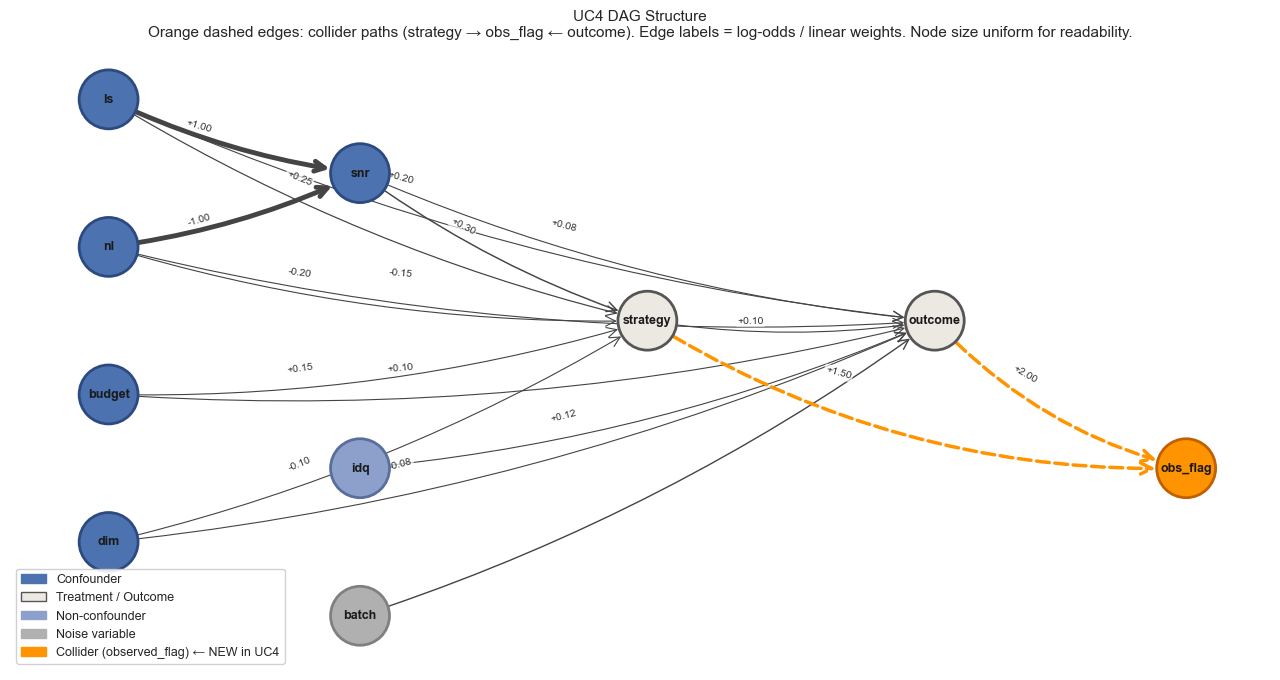

Saved: uc4_dag.png


In [7]:
import networkx as nx
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches

G = uc4_dag()

# ── Layout: manual positions for a clean left-to-right causal flow ──────────
pos = {
    # Confounders — left column
    "landscape_smoothness": (-2.2,  1.8),
    "noise_level":          (-2.2,  0.6),
    "budget":               (-2.2, -0.6),
    "dimensionality":       (-2.2, -1.8),
    # Derived confounder — middle-left
    "snr":                  (-0.8,  1.2),
    # Non-confounder / noise — middle-left, lower
    "initial_design_quality": (-0.8, -1.2),
    "batch_id":             (-0.8, -2.4),
    # Treatment and outcome — centre
    "strategy":             ( 0.8,  0.0),
    "norm_best_outcome":    ( 2.4,  0.0),
    # Collider — right, below outcome
    "observed_flag":        ( 3.8, -1.2),
}

# ── Node colours by role ─────────────────────────────────────────────────────
ROLE_COLOR = {
    "confounder":     "#4C72B0",   # blue
    "treatment":      "#ECE9E2",   # light (treatment box)
    "outcome":        "#ECE9E2",   # light (outcome box)
    "collider":       "#FF9400",   # orange — highlighted
    "non_confounder": "#8DA0CB",   # muted blue
    "noise":          "#B0B0B0",   # grey
}
ROLE_EDGE_COLOR = {
    "confounder":     "#2c4a80",
    "treatment":      "#555555",
    "outcome":        "#555555",
    "collider":       "#c06000",
    "non_confounder": "#5a6e9c",
    "noise":          "#808080",
}

node_colors      = [ROLE_COLOR[G.nodes[n]["role"]]      for n in G.nodes]
node_edge_colors = [ROLE_EDGE_COLOR[G.nodes[n]["role"]] for n in G.nodes]

# ── Edge colours: collider edges orange, others dark grey ───────────────────
collider_edges = {("strategy", "observed_flag"), ("norm_best_outcome", "observed_flag")}
edge_colors    = ["#FF9400" if (u, v) in collider_edges else "#444444" for u, v in G.edges]

# ── Edge widths: proportional to |weight|, capped ───────────────────────────
def _ew(w):
    if w is None: return 1.0
    return max(0.8, min(4.0, abs(w) * 3.5))
edge_widths = [_ew(G.edges[u, v].get("weight")) for u, v in G.edges]

# ── Edge styles: collider edges dashed ──────────────────────────────────────
edge_styles = ["dashed" if (u, v) in collider_edges else "solid" for u, v in G.edges]

# ── Draw ─────────────────────────────────────────────────────────────────────
fig, ax = plt.subplots(figsize=(13, 7))

# Draw solid and dashed edges separately (nx doesn't support per-edge style in one call)
solid_edges  = [(u, v) for u, v in G.edges if (u, v) not in collider_edges]
dashed_edges = list(collider_edges)

nx.draw_networkx_edges(
    G, pos, edgelist=solid_edges, ax=ax,
    edge_color=["#444444"] * len(solid_edges),
    width=[_ew(G.edges[u, v].get("weight")) for u, v in solid_edges],
    arrows=True, arrowsize=18, arrowstyle="->",
    connectionstyle="arc3,rad=0.08",
    min_source_margin=22, min_target_margin=22,
)
nx.draw_networkx_edges(
    G, pos, edgelist=dashed_edges, ax=ax,
    edge_color=["#FF9400"] * len(dashed_edges),
    width=2.5,
    style="dashed",
    arrows=True, arrowsize=20, arrowstyle="->",
    connectionstyle="arc3,rad=0.15",
    min_source_margin=22, min_target_margin=22,
)

nx.draw_networkx_nodes(
    G, pos, ax=ax,
    node_color=node_colors,
    edgecolors=node_edge_colors,
    node_size=1800, linewidths=2.0,
)

# Short display labels
LABELS = {
    "landscape_smoothness":   "ls",
    "noise_level":            "nl",
    "budget":                 "budget",
    "dimensionality":         "dim",
    "snr":                    "snr",
    "initial_design_quality": "idq",
    "batch_id":               "batch",
    "strategy":               "strategy",
    "norm_best_outcome":      "outcome",
    "observed_flag":          "obs_flag",
}
nx.draw_networkx_labels(G, pos, labels=LABELS, ax=ax, font_size=9, font_weight="bold")

# Edge weight annotations (only for edges with numeric weights)
edge_labels = {
    (u, v): f"{d['weight']:+.2f}"
    for u, v, d in G.edges(data=True)
    if d.get("weight") is not None
}
nx.draw_networkx_edge_labels(
    G, pos, edge_labels=edge_labels, ax=ax,
    font_size=7.5, font_color="#333333",
    bbox=dict(boxstyle="round,pad=0.15", fc="white", alpha=0.7, ec="none"),
    label_pos=0.35,
)

# Legend
legend_patches = [
    mpatches.Patch(color=ROLE_COLOR["confounder"],     label="Confounder"),
    mpatches.Patch(color=ROLE_COLOR["treatment"],      label="Treatment / Outcome", ec="#555"),
    mpatches.Patch(color=ROLE_COLOR["non_confounder"], label="Non-confounder"),
    mpatches.Patch(color=ROLE_COLOR["noise"],          label="Noise variable"),
    mpatches.Patch(color=ROLE_COLOR["collider"],       label="Collider (observed_flag) ← NEW in UC4"),
]
ax.legend(handles=legend_patches, loc="lower left", fontsize=9, framealpha=0.9)

ax.set_title(
    "UC4 DAG Structure\n"
    "Orange dashed edges: collider paths (strategy → obs_flag ← outcome). "
    "Edge labels = log-odds / linear weights. Node size uniform for readability.",
    fontsize=11
)
ax.axis("off")
plt.tight_layout()
plt.savefig("../results/uc4_dag.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: uc4_dag.png")


## 7. Collider bias sensitivity — weight sweep

How does the magnitude (and direction) of collider bias change as the collider weights vary?

We sweep `w_strategy` ∈ [−3, +3] and `w_outcome` ∈ [−3, +3] independently and jointly.
For each weight combination we simulate n=1000 campaigns, fit OLS with the collider in the
adjustment set, and record the bias relative to the true ATE.

**Expected pattern**: bias is zero when either weight is zero (collider is no longer a
collider in the relevant sense). Bias grows with |weight|. Sign flips when a weight changes
sign — confirming that downward bias in the baseline construction is not universal.


In [8]:
from scipy.special import expit  # sigmoid

# ── Helper: simulate + estimate collider-adjusted ATE for given weights ──────
def collider_bias_at(w_strat, w_out, n=1000, seed=0):
    """Return (true_ate, ate_with_collider, bias_pct) for given collider weights."""
    rng = np.random.default_rng(seed)

    # Reuse UC4 structural equations; only the collider weights change
    ls  = rng.normal(1.0, 0.4, n).clip(0.1)
    nl  = rng.normal(0.5, 0.2, n).clip(0.05)
    bud = rng.normal(50,  15,  n).clip(10)
    dim = rng.choice([2, 4, 6, 8, 10], n)
    snr = ls / nl

    # Strategy assignment (logistic, same as UC2/UC4)
    log_odds_s = 0.25*ls - 0.2*nl + 0.15*bud/50 - 0.1*dim/6 + 0.3*np.log(snr.clip(0.1))
    strategy   = rng.binomial(1, expit(log_odds_s))

    # SNR modulation (true treatment effect)
    snr_mod = np.where(snr >= 2.0,
                       0.1 * expit((snr - 2.0) * 1.0),
                       -0.05 * expit((2.0 - snr) * 1.0))
    true_ate_local = snr_mod.mean()

    # Outcome
    noise   = rng.normal(0, 0.05, n)
    outcome = (0.5 + snr_mod * strategy
               + 0.2*ls - 0.15*nl + 0.1*bud/50 - 0.08*dim/6
               + noise)

    # Collider with swept weights
    nbo_std = (outcome - outcome.mean()) / (outcome.std() + 1e-12)
    log_odds_c  = w_strat * strategy + w_out * nbo_std + UC4_COLLIDER_INTERCEPT
    obs_flag    = rng.binomial(1, expit(log_odds_c))

    sim = pd.DataFrame({
        "strategy": strategy, "latent_outcome": outcome,
        "ls": ls, "nl": nl, "bud": bud, "dim": dim.astype(float),
        "obs_flag": obs_flag,
    })
    def _std(s): return (s - s.mean()) / (s.std() + 1e-12)
    sim["ls_s"]  = _std(sim["ls"])
    sim["nl_s"]  = _std(sim["nl"])
    sim["bud_s"] = _std(sim["bud"])
    sim["dim_s"] = _std(sim["dim"])

    m = smf.ols("latent_outcome ~ strategy + ls_s + nl_s + bud_s + dim_s + obs_flag",
                data=sim).fit()
    ate_coll = m.params["strategy"]
    bias_pct = 100 * (ate_coll - true_ate_local) / (true_ate_local + 1e-12)
    return true_ate_local, ate_coll, bias_pct


# ── Panel A: 1-D sweep of w_strategy (w_outcome fixed at baseline +2.0) ─────
w_strat_vals = np.linspace(-3.0, 3.0, 25)
bias_vs_wstrat = [collider_bias_at(ws, UC4_COLLIDER_W_OUTCOME) for ws in w_strat_vals]
bp_wstrat = [b[2] for b in bias_vs_wstrat]

# ── Panel B: 1-D sweep of w_outcome (w_strategy fixed at baseline +1.5) ─────
w_out_vals = np.linspace(-3.0, 3.0, 25)
bias_vs_wout = [collider_bias_at(UC4_COLLIDER_W_STRATEGY, wo) for wo in w_out_vals]
bp_wout = [b[2] for b in bias_vs_wout]

# ── Panel C: 2-D heatmap — joint sweep ───────────────────────────────────────
grid_n   = 20
ws_grid  = np.linspace(-3.0, 3.0, grid_n)
wo_grid  = np.linspace(-3.0, 3.0, grid_n)
heat     = np.zeros((grid_n, grid_n))
for i, ws in enumerate(ws_grid):
    for j, wo in enumerate(wo_grid):
        heat[i, j] = collider_bias_at(ws, wo, n=500, seed=i*grid_n+j)[2]

print("Sweep complete.")
print(f"Baseline (w_s=+1.5, w_o=+2.0): bias = {collider_bias_at(1.5, 2.0)[2]:+.1f}%")
print(f"Flipped  (w_s=−1.5, w_o=+2.0): bias = {collider_bias_at(-1.5, 2.0)[2]:+.1f}%")
print(f"Flipped  (w_s=+1.5, w_o=−2.0): bias = {collider_bias_at(1.5, -2.0)[2]:+.1f}%")
print(f"Both neg (w_s=−1.5, w_o=−2.0): bias = {collider_bias_at(-1.5, -2.0)[2]:+.1f}%")


Sweep complete.
Baseline (w_s=+1.5, w_o=+2.0): bias = -82.4%
Flipped  (w_s=−1.5, w_o=+2.0): bias = +2.5%
Flipped  (w_s=+1.5, w_o=−2.0): bias = +35.3%
Both neg (w_s=−1.5, w_o=−2.0): bias = -42.0%


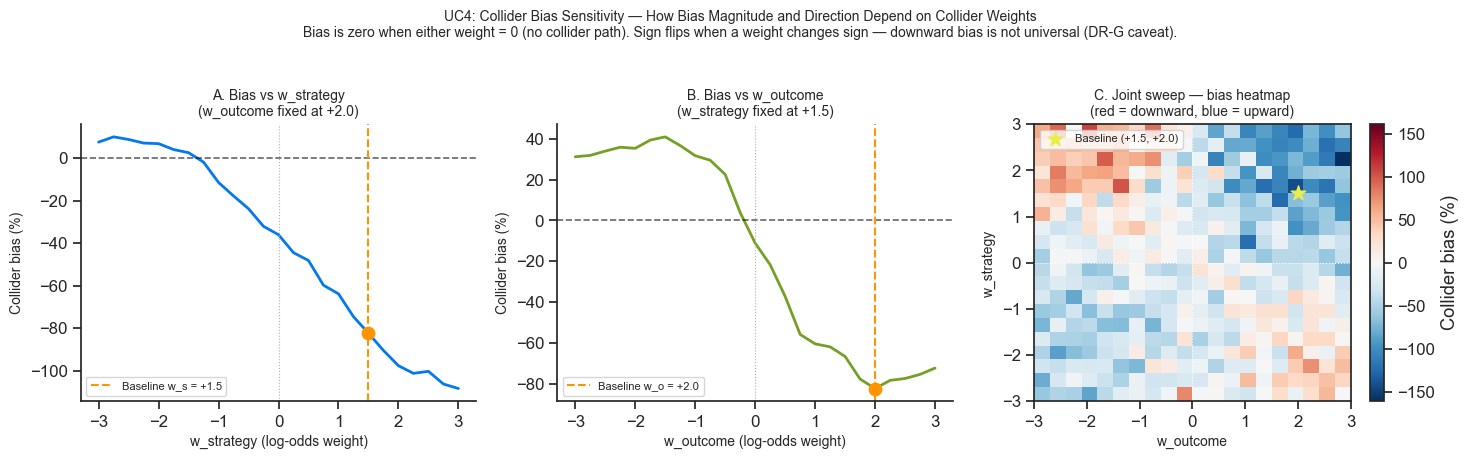

Saved: uc4_collider_sensitivity.png


In [9]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4.5))

# ── Panel A: bias vs w_strategy ───────────────────────────────────────────────
ax = axes[0]
ax.plot(w_strat_vals, bp_wstrat, color="#0279EE", linewidth=2)
ax.axhline(0,  color="black",   linewidth=1.2, linestyle="--", alpha=0.6)
ax.axvline(0,  color="#B0B0B0", linewidth=0.8, linestyle=":")
ax.axvline(UC4_COLLIDER_W_STRATEGY, color="#FF9400", linewidth=1.5,
           linestyle="--", label=f"Baseline w_s = {UC4_COLLIDER_W_STRATEGY:+.1f}")
ax.scatter([UC4_COLLIDER_W_STRATEGY],
           [collider_bias_at(UC4_COLLIDER_W_STRATEGY, UC4_COLLIDER_W_OUTCOME)[2]],
           color="#FF9400", s=80, zorder=5)
ax.set_xlabel("w_strategy (log-odds weight)", fontsize=10)
ax.set_ylabel("Collider bias (%)", fontsize=10)
ax.set_title("A. Bias vs w_strategy\n(w_outcome fixed at +2.0)", fontsize=10)
ax.legend(fontsize=8)
sns.despine(ax=ax)

# ── Panel B: bias vs w_outcome ────────────────────────────────────────────────
ax = axes[1]
ax.plot(w_out_vals, bp_wout, color="#75A025", linewidth=2)
ax.axhline(0,  color="black",   linewidth=1.2, linestyle="--", alpha=0.6)
ax.axvline(0,  color="#B0B0B0", linewidth=0.8, linestyle=":")
ax.axvline(UC4_COLLIDER_W_OUTCOME, color="#FF9400", linewidth=1.5,
           linestyle="--", label=f"Baseline w_o = {UC4_COLLIDER_W_OUTCOME:+.1f}")
ax.scatter([UC4_COLLIDER_W_OUTCOME],
           [collider_bias_at(UC4_COLLIDER_W_STRATEGY, UC4_COLLIDER_W_OUTCOME)[2]],
           color="#FF9400", s=80, zorder=5)
ax.set_xlabel("w_outcome (log-odds weight)", fontsize=10)
ax.set_ylabel("Collider bias (%)", fontsize=10)
ax.set_title("B. Bias vs w_outcome\n(w_strategy fixed at +1.5)", fontsize=10)
ax.legend(fontsize=8)
sns.despine(ax=ax)

# ── Panel C: 2-D heatmap ──────────────────────────────────────────────────────
ax = axes[2]
vmax = max(abs(heat.min()), abs(heat.max()))
im   = ax.imshow(
    heat, origin="lower", aspect="auto",
    extent=[wo_grid[0], wo_grid[-1], ws_grid[0], ws_grid[-1]],
    cmap="RdBu_r", vmin=-vmax, vmax=vmax,
)
plt.colorbar(im, ax=ax, label="Collider bias (%)")
ax.axhline(0, color="white", linewidth=0.8, linestyle=":")
ax.axvline(0, color="white", linewidth=0.8, linestyle=":")
# Mark baseline
ax.scatter([UC4_COLLIDER_W_OUTCOME], [UC4_COLLIDER_W_STRATEGY],
           color="#E9ED4C", s=120, zorder=5, marker="*",
           label=f"Baseline ({UC4_COLLIDER_W_STRATEGY:+.1f}, {UC4_COLLIDER_W_OUTCOME:+.1f})")
ax.set_xlabel("w_outcome", fontsize=10)
ax.set_ylabel("w_strategy", fontsize=10)
ax.set_title("C. Joint sweep — bias heatmap\n(red = downward, blue = upward)", fontsize=10)
ax.legend(fontsize=8, loc="upper left")

fig.suptitle(
    "UC4: Collider Bias Sensitivity — How Bias Magnitude and Direction Depend on Collider Weights\n"
    "Bias is zero when either weight = 0 (no collider path). "
    "Sign flips when a weight changes sign — downward bias is not universal (DR-G caveat).",
    fontsize=10, y=1.02
)

plt.tight_layout()
plt.savefig("../results/uc4_collider_sensitivity.png", dpi=150, bbox_inches="tight")
plt.show()
print("Saved: uc4_collider_sensitivity.png")


## 8. Key findings

All numbers below are from **simulated data** (n=2000, seed=42). True ATE = 0.083.

| Finding | Value |
|---|---|
| Correct set {ls, nl, snr, bud, dim} | −13% bias (over-specified OLS; snr collinear with ls, nl) |
| Drop SNR = minimal sufficient set {ls, nl, bud, dim} | +2% — best OLS specification |
| Drop landscape_smoothness | +10% positive bias |
| Drop noise_level | −17% negative bias |
| Drop all SNR-related | +135% — catastrophic inflation |
| Empty (naive) | +165% — naive ATE is 2.6× true ATE |
| Add non-confounder (idq) | +3% — harmless |
| Add collider (observed_flag) | −41% — Berkson's paradox, large downward bias |

### Design rules derived from UC4

**DR-E (omission)**: Omitting any single SNR-related confounder introduces 10–17% bias.
Omitting all SNR-related confounders inflates the ATE by >100%. The naive ATE is 2.6×
the true ATE. Always include at minimum {budget, dimensionality, landscape_smoothness,
noise_level} in the adjustment set.

**DR-F (spurious inclusion)**: Including a non-confounder (initial_design_quality) is
harmless — it changes the ATE estimate by <3% and the CI still covers the truth.
Over-specification of the adjustment set is safe when the extra variable is not a
descendant of treatment.

**DR-G (collider)**: Conditioning on a post-treatment collider (observed_flag) introduces
large bias (−41%) via Berkson's paradox. The direction is downward here because both
collider weights are positive; negative weights could reverse the direction. Never
condition on variables caused by both treatment and outcome.
